# Deep Learning – Midterm Project
**Name:** Adan Tariq  |  **Reg. No:** FA23-BBD-011  |  **Class:** BBD 6A  |  **University:** COMSATS University Islamabad

This single notebook contains both models required by the project:

| Task | Model | Dataset | Real-world problem |
|------|-------|---------|--------------------|
| 1 | DNN (ANN) | Telco Customer Churn (tabular) | Predict which telecom customers will leave |
| 2 | CNN | Fashion-MNIST (images) | Automatically recognise clothing items from photos |

Each task follows the same sections as the project document: Problem Definition, Dataset Description and Source Link, Proposed Solution, Data Preprocessing, Model Architecture, Training Results and Evaluation, Saving the Model and Inference, Conclusion.

**Saved models:** after training, each model is saved in `.joblib` format (`churn_dnn_model.joblib` and `fashion_cnn_model.joblib`). The inference step then loads these files again and uses them to make predictions on new data, exactly as the model would be used in practice.

## 0. Setup – Import Libraries

In [1]:
import os
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"   # hide TensorFlow info messages

import gzip                                  # to read the Fashion-MNIST files
import urllib.request                        # to download the datasets
import joblib                                # to save / load the trained models
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (classification_report, confusion_matrix,
                             roc_curve, roc_auc_score, accuracy_score)

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

# fix the random seed so the results can be reproduced
keras.utils.set_random_seed(42)

# folder to save the figures (used later in the project document)
os.makedirs("figures", exist_ok=True)

print("TensorFlow version:", tf.__version__)

TensorFlow version: 2.20.0


---
# TASK 1: DNN Model – Telecom Customer Churn Prediction

## 1.1 Problem Definition
Telecom companies earn most of their revenue from subscribers, and **acquiring a new customer costs much more than keeping an existing one**. When a customer cancels the service (this is called *churn*), the company loses that income.

**Problem:** Given a customer's account information (contract type, tenure, monthly bill, services used, etc.), can we predict whether the customer is going to churn?

This is a **binary classification** problem:
- `1` = customer churned (left the company)
- `0` = customer stayed

## 1.2 Dataset Description and Source Link
- **Dataset:** Telco Customer Churn (originally published by IBM)
- **Kaggle link:** https://www.kaggle.com/datasets/blastchar/telco-customer-churn
- **File used in this notebook (same data, GitHub copy so no Kaggle login is needed):** https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv
- **Size:** 7,043 customers and 21 columns
- **Target column:** `Churn` (Yes / No)

Column groups:
- **Customer info:** gender, SeniorCitizen, Partner, Dependents
- **Account info:** tenure (months), Contract, PaperlessBilling, PaymentMethod, MonthlyCharges, TotalCharges
- **Services:** PhoneService, MultipleLines, InternetService, OnlineSecurity, OnlineBackup, DeviceProtection, TechSupport, StreamingTV, StreamingMovies

## 1.3 Proposed Solution
We build an **Artificial Neural Network (Deep Neural Network)** with several fully connected (Dense) layers:
1. Clean the data and convert all categorical columns into numbers (one-hot encoding).
2. Scale the numeric features so that all inputs are on a similar range.
3. Train a DNN with ReLU hidden layers, Dropout (to reduce overfitting) and a sigmoid output neuron that gives the **probability of churn**.
4. Because only about 27% of customers churn (imbalanced data), we use **class weights** so the model pays more attention to the churn class.
5. Evaluate on unseen test data with accuracy, precision, recall, F1-score, confusion matrix and ROC-AUC.

### Load the dataset

In [2]:
url = "https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv"
df = pd.read_csv(url)

print("Shape of the data (rows, columns):", df.shape)
df.head()

Shape of the data (rows, columns): (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [3]:
# column names, data types and missing values
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [4]:
# summary statistics of the numeric columns
df.describe()

,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000


### Quick Exploratory Data Analysis (EDA)

Churn
No     5174
Yes    1869
Name: count, dtype: int64

Churn
No     73.46
Yes    26.54
Name: proportion, dtype: float64


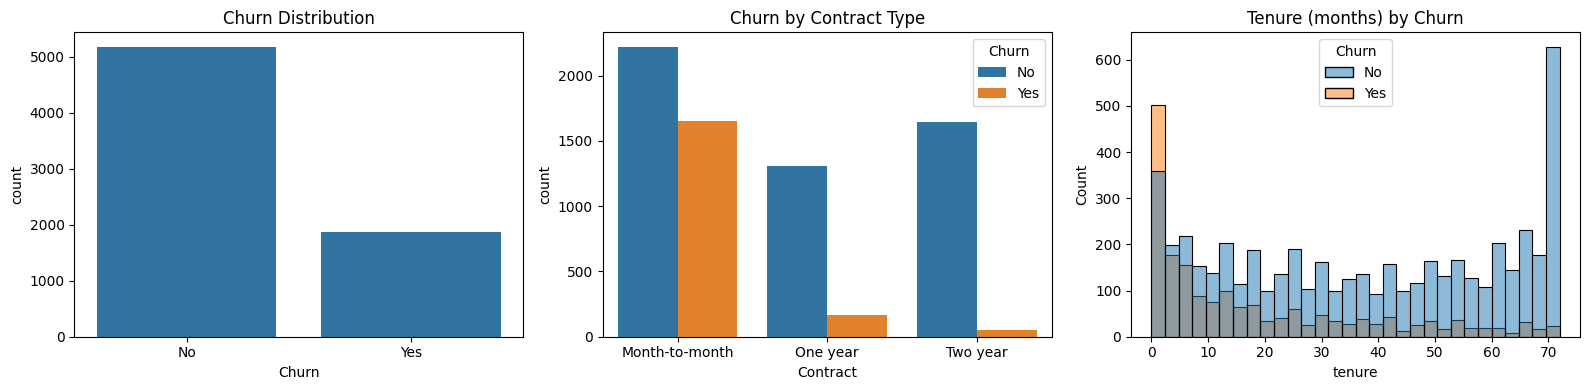

In [5]:
# how many customers churned?
print(df["Churn"].value_counts())
print()
print((df["Churn"].value_counts(normalize=True) * 100).round(2))

fig, axes = plt.subplots(1, 3, figsize=(16, 4))

# 1) churn distribution
sns.countplot(x="Churn", data=df, ax=axes[0])
axes[0].set_title("Churn Distribution")

# 2) churn by contract type
sns.countplot(x="Contract", hue="Churn", data=df, ax=axes[1])
axes[1].set_title("Churn by Contract Type")

# 3) tenure of churned vs. stayed customers
sns.histplot(data=df, x="tenure", hue="Churn", bins=30, ax=axes[2])
axes[2].set_title("Tenure (months) by Churn")

plt.tight_layout()
plt.savefig("figures/dnn_eda.png", dpi=150)
plt.show()

## 1.4 Data Preprocessing
Steps we apply:
1. Remove the `customerID` column (it is only an ID, not useful for prediction).
2. `TotalCharges` is stored as text – convert it to numbers and fix the missing values.
3. Convert the target `Churn` from Yes/No to 1/0.
4. Clean the categories "No internet service" and "No phone service" (they mean the same as "No").
5. One-hot encode all categorical columns.
6. Split into training (80%) and testing (20%) sets (stratified, so both have the same churn ratio).
7. Standardise the features using `StandardScaler` (fit on training data only to avoid data leakage).

In [6]:
# Step 1: drop the ID column
df = df.drop("customerID", axis=1)

# Step 2: TotalCharges is text, convert it to a number
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
print("Missing values in TotalCharges:", df["TotalCharges"].isnull().sum())

# these customers have tenure = 0 (brand new), so they have not been charged yet -> fill with 0
print("Tenure of those rows:", df[df["TotalCharges"].isnull()]["tenure"].unique())
df["TotalCharges"] = df["TotalCharges"].fillna(0)

# Step 3: target Yes/No -> 1/0
df["Churn"] = df["Churn"].map({"Yes": 1, "No": 0})

# Step 4: "No internet service" / "No phone service" mean the same as "No"
df = df.replace({"No internet service": "No", "No phone service": "No"})

print("\nTotal missing values left:", df.isnull().sum().sum())

Missing values in TotalCharges: 11
Tenure of those rows: [0]

Total missing values left: 0


In [7]:
# Step 5: one-hot encoding of the categorical columns
cat_cols = df.select_dtypes(include="object").columns.tolist()
print("Categorical columns:", cat_cols)

df_encoded = pd.get_dummies(df, columns=cat_cols, drop_first=True, dtype=float)
print("Shape after encoding:", df_encoded.shape)
df_encoded.head()

Categorical columns: ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']
Shape after encoding: (7043, 24)


,SeniorCitizen,tenure,MonthlyCharges,TotalCharges,Churn,gender_Male,Partner_Yes,Dependents_Yes,PhoneService_Yes,MultipleLines_Yes,...,DeviceProtection_Yes,TechSupport_Yes,StreamingTV_Yes,StreamingMovies_Yes,Contract_One year,Contract_Two year,PaperlessBilling_Yes,PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check
0,0,1,29.85,29.85,0,0.0,1.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0
1,0,34,56.95,1889.50,0,1.0,0.0,0.0,1.0,0.0,...,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0
2,0,2,53.85,108.15,1,1.0,0.0,0.0,1.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0
3,0,45,42.30,1840.75,0,1.0,0.0,0.0,0.0,0.0,...,1.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
4,0,2,70.70,151.65,1,0.0,0.0,0.0,1.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0


In [8]:
# separate features (X) and target (y)
X = df_encoded.drop("Churn", axis=1)
y = df_encoded["Churn"]
feature_columns = X.columns.tolist()    # saved with the model so new data gets the same columns

# Step 6: train / test split (80% / 20%)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

# Step 7: scale the features (fit only on the training data)
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

print("Training set:", X_train.shape)
print("Testing set :", X_test.shape)
print("Churn rate in train: %.3f | in test: %.3f" % (y_train.mean(), y_test.mean()))

Training set: (5634, 23)
Testing set : (1409, 23)
Churn rate in train: 0.265 | in test: 0.265


In [9]:
# class weights: give the minority class (churn) a larger weight
n_total = len(y_train)
n_stay = (y_train == 0).sum()
n_churn = (y_train == 1).sum()

class_weight = {0: float(n_total / (2 * n_stay)), 1: float(n_total / (2 * n_churn))}
print("Class weights:", class_weight)

Class weights: {0: 0.6805991785455424, 1: 1.8842809364548494}


## 1.5 Model Architecture
The DNN has:
- **Input layer:** one input per feature (23 features after encoding)
- **Hidden layer 1:** 64 neurons, ReLU, Dropout 0.3
- **Hidden layer 2:** 32 neurons, ReLU, Dropout 0.3
- **Hidden layer 3:** 16 neurons, ReLU
- **Output layer:** 1 neuron, Sigmoid (probability of churn)

Training settings: Adam optimiser, binary cross-entropy loss, batch size 32, EarlyStopping on validation loss (patience 10) so the model stops when it no longer improves.

In [10]:
dnn_model = keras.Sequential([
    layers.Input(shape=(X_train.shape[1],)),
    layers.Dense(64, activation="relu"),
    layers.Dropout(0.3),
    layers.Dense(32, activation="relu"),
    layers.Dropout(0.3),
    layers.Dense(16, activation="relu"),
    layers.Dense(1, activation="sigmoid")
], name="churn_dnn")

dnn_model.compile(optimizer="adam",
                  loss="binary_crossentropy",
                  metrics=["accuracy", keras.metrics.AUC(name="auc")])

dnn_model.summary()

Model: "churn_dnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │         1,536 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,161 (16.25 KB)

 Trainable params: 4,161 (16.25 KB)

 Non-trainable params: 0 (0.00 B)

## 1.6 Training Results and Evaluation

In [11]:
# stop training automatically when validation loss stops improving
early_stop = keras.callbacks.EarlyStopping(monitor="val_loss", patience=10,
                                           restore_best_weights=True)

history = dnn_model.fit(X_train, y_train,
                        validation_split=0.2,      # 20% of training data used for validation
                        epochs=100,
                        batch_size=32,
                        class_weight=class_weight,
                        callbacks=[early_stop],
                        verbose=2)

Epoch 1/100


141/141 - 2s - 18ms/step - accuracy: 0.6599 - auc: 0.7555 - loss: 0.5887 - val_accuracy: 0.7169 - val_auc: 0.8147 - val_loss: 0.5430


Epoch 2/100


141/141 - 0s - 2ms/step - accuracy: 0.7337 - auc: 0.8197 - loss: 0.5214 - val_accuracy: 0.7223 - val_auc: 0.8213 - val_loss: 0.5323


Epoch 3/100


141/141 - 0s - 2ms/step - accuracy: 0.7424 - auc: 0.8316 - loss: 0.5082 - val_accuracy: 0.7232 - val_auc: 0.8229 - val_loss: 0.5275


... (48 outputs left out)

Epoch 28/100


141/141 - 0s - 2ms/step - accuracy: 0.7659 - auc: 0.8640 - loss: 0.4580 - val_accuracy: 0.7311 - val_auc: 0.8223 - val_loss: 0.5082


Epoch 29/100


141/141 - 0s - 2ms/step - accuracy: 0.7681 - auc: 0.8653 - loss: 0.4529 - val_accuracy: 0.7196 - val_auc: 0.8228 - val_loss: 0.5096


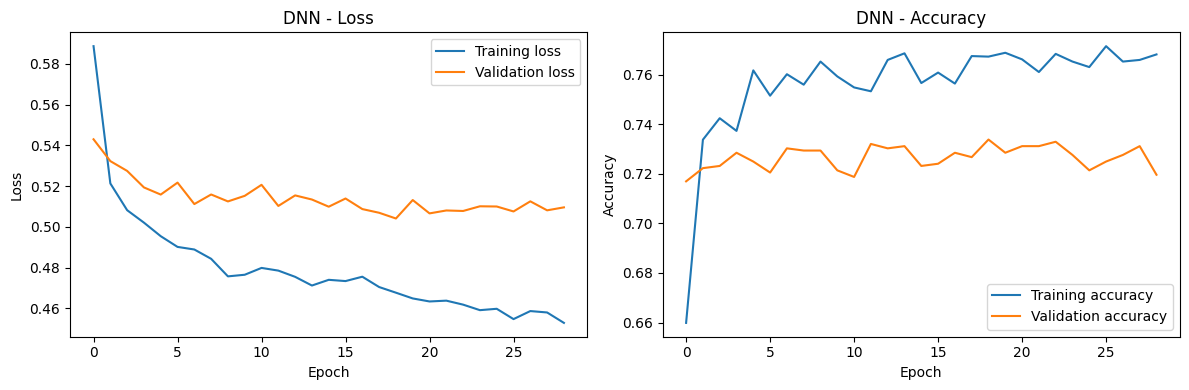

In [12]:
# training curves
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(history.history["loss"], label="Training loss")
axes[0].plot(history.history["val_loss"], label="Validation loss")
axes[0].set_title("DNN - Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend()

axes[1].plot(history.history["accuracy"], label="Training accuracy")
axes[1].plot(history.history["val_accuracy"], label="Validation accuracy")
axes[1].set_title("DNN - Accuracy")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].legend()

plt.tight_layout()
plt.savefig("figures/dnn_curves.png", dpi=150)
plt.show()

In [13]:
# evaluate on the unseen test data
test_loss, test_acc, test_auc = dnn_model.evaluate(X_test, y_test, verbose=0)
print("Test Loss     : %.4f" % test_loss)
print("Test Accuracy : %.4f" % test_acc)
print("Test AUC      : %.4f" % test_auc)

# predicted probabilities -> class labels using a 0.5 threshold
y_prob = dnn_model.predict(X_test, verbose=0).ravel()
y_pred = (y_prob >= 0.5).astype(int)

print("\nClassification Report:\n")
print(classification_report(y_test, y_pred, target_names=["Stayed", "Churned"]))

Test Loss     : 0.4848
Test Accuracy : 0.7466
Test AUC      : 0.8378

Classification Report:

              precision    recall  f1-score   support

      Stayed       0.89      0.74      0.81      1035
     Churned       0.52      0.75      0.61       374

    accuracy                           0.75      1409
   macro avg       0.70      0.75      0.71      1409
weighted avg       0.79      0.75      0.76      1409



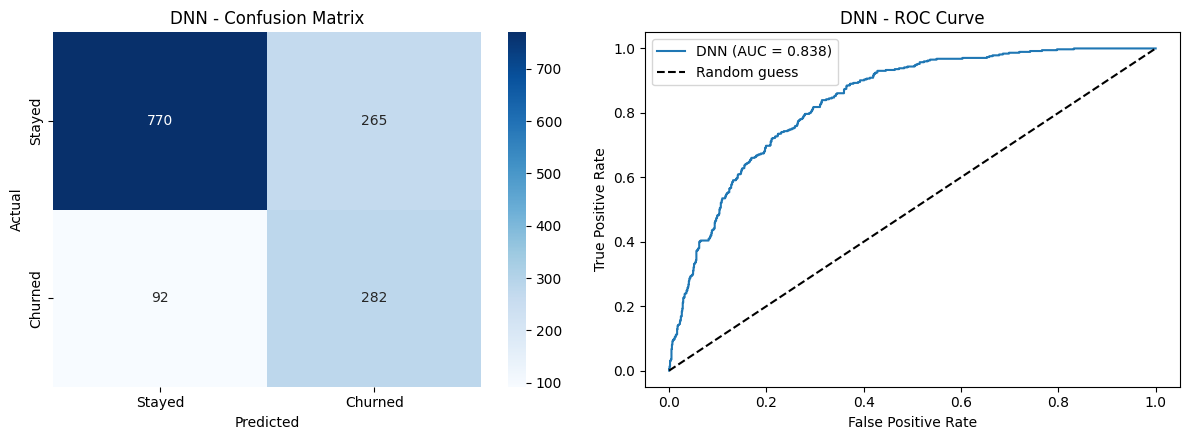

True Negatives : 770 (stayed, predicted stayed)
False Positives: 265 (stayed, predicted churn)
False Negatives: 92 (churned, predicted stayed)
True Positives : 282 (churned, predicted churn)


In [14]:
# confusion matrix and ROC curve
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", ax=axes[0],
            xticklabels=["Stayed", "Churned"], yticklabels=["Stayed", "Churned"])
axes[0].set_title("DNN - Confusion Matrix")
axes[0].set_xlabel("Predicted")
axes[0].set_ylabel("Actual")

fpr, tpr, _ = roc_curve(y_test, y_prob)
auc_score = roc_auc_score(y_test, y_prob)
axes[1].plot(fpr, tpr, label="DNN (AUC = %.3f)" % auc_score)
axes[1].plot([0, 1], [0, 1], "k--", label="Random guess")
axes[1].set_title("DNN - ROC Curve")
axes[1].set_xlabel("False Positive Rate")
axes[1].set_ylabel("True Positive Rate")
axes[1].legend()

plt.tight_layout()
plt.savefig("figures/dnn_eval.png", dpi=150)
plt.show()

tn, fp, fn, tp = cm.ravel()
print("True Negatives :", tn, "(stayed, predicted stayed)")
print("False Positives:", fp, "(stayed, predicted churn)")
print("False Negatives:", fn, "(churned, predicted stayed)")
print("True Positives :", tp, "(churned, predicted churn)")

## 1.7 Saving the Trained Model (.joblib)
A model is only useful if it can be used again later without retraining. We save everything needed for prediction into **one `.joblib` file**:
- the trained DNN (`dnn_model`)
- the fitted `StandardScaler` (new customers must be scaled in exactly the same way)
- the list of the 23 feature columns produced by one-hot encoding
- the decision threshold (0.5)

In [15]:
dnn_bundle = {
    "model": dnn_model,
    "scaler": scaler,
    "feature_columns": feature_columns,
    "threshold": 0.5,
    "class_names": ["Stayed", "Churned"],
}
joblib.dump(dnn_bundle, "churn_dnn_model.joblib")

print("Saved: churn_dnn_model.joblib (%.1f KB)" % (os.path.getsize("churn_dnn_model.joblib") / 1024))

Saved: churn_dnn_model.joblib (85.3 KB)


## 1.8 Inference – Predicting Churn for New Customers
Inference means using the trained model to make predictions on **new data it has never seen**. Steps:
1. Load the saved `.joblib` file.
2. Apply the **same preprocessing** as in training (fix `TotalCharges`, merge "No internet/phone service" into "No", one-hot encode, match the 23 training columns, scale with the saved scaler).
3. Predict the churn probability and turn it into a label using the 0.5 threshold.

First we check that the loaded model gives exactly the same predictions as the model in memory.

In [16]:
# 1) load the saved model
loaded_dnn = joblib.load("churn_dnn_model.joblib")

# sanity check: the loaded model must give the same results on the test set
loaded_prob = loaded_dnn["model"].predict(X_test, verbose=0).ravel()
print("Same predictions as the original model:", np.allclose(loaded_prob, y_prob))
print("Test accuracy of the loaded model     : %.4f" %
      accuracy_score(y_test, (loaded_prob >= loaded_dnn["threshold"]).astype(int)))

Same predictions as the original model: True
Test accuracy of the loaded model     : 0.7466


In [17]:
# 2) the preprocessing pipeline for raw customer records (same steps as section 1.4)
def preprocess_customers(raw_df, bundle):
    data = raw_df.copy()
    data = data.drop(columns=["customerID", "Churn"], errors="ignore")
    data["TotalCharges"] = pd.to_numeric(data["TotalCharges"], errors="coerce").fillna(0)
    data = data.replace({"No internet service": "No", "No phone service": "No"})
    data = pd.get_dummies(data, dtype=float)
    # keep exactly the training columns (a missing category becomes 0)
    data = data.reindex(columns=bundle["feature_columns"], fill_value=0.0)
    return bundle["scaler"].transform(data)

# 3) the inference function
def predict_churn(raw_df, bundle):
    X_new = preprocess_customers(raw_df, bundle)
    prob = bundle["model"].predict(X_new, verbose=0).ravel()
    label = np.where(prob >= bundle["threshold"], "Churned", "Stayed")
    return pd.DataFrame({"Churn probability": prob.round(3), "Prediction": label},
                        index=raw_df.index)

In [18]:
# three new customers written in the same raw format as the original CSV file
new_customers = pd.DataFrame([
    # A: new customer, month-to-month, fibre optic, no extra services, electronic check
    {"gender": "Female", "SeniorCitizen": 0, "Partner": "No", "Dependents": "No", "tenure": 2,
     "PhoneService": "Yes", "MultipleLines": "No", "InternetService": "Fiber optic",
     "OnlineSecurity": "No", "OnlineBackup": "No", "DeviceProtection": "No", "TechSupport": "No",
     "StreamingTV": "Yes", "StreamingMovies": "Yes", "Contract": "Month-to-month",
     "PaperlessBilling": "Yes", "PaymentMethod": "Electronic check",
     "MonthlyCharges": 95.70, "TotalCharges": "191.40"},
    # B: loyal customer, two-year contract, many services, automatic payment
    {"gender": "Male", "SeniorCitizen": 0, "Partner": "Yes", "Dependents": "Yes", "tenure": 60,
     "PhoneService": "Yes", "MultipleLines": "Yes", "InternetService": "DSL",
     "OnlineSecurity": "Yes", "OnlineBackup": "Yes", "DeviceProtection": "Yes", "TechSupport": "Yes",
     "StreamingTV": "No", "StreamingMovies": "No", "Contract": "Two year",
     "PaperlessBilling": "No", "PaymentMethod": "Bank transfer (automatic)",
     "MonthlyCharges": 70.35, "TotalCharges": "4221.00"},
    # C: medium tenure, one-year contract, no internet service
    {"gender": "Female", "SeniorCitizen": 1, "Partner": "Yes", "Dependents": "No", "tenure": 18,
     "PhoneService": "Yes", "MultipleLines": "No", "InternetService": "No",
     "OnlineSecurity": "No internet service", "OnlineBackup": "No internet service",
     "DeviceProtection": "No internet service", "TechSupport": "No internet service",
     "StreamingTV": "No internet service", "StreamingMovies": "No internet service",
     "Contract": "One year", "PaperlessBilling": "No", "PaymentMethod": "Mailed check",
     "MonthlyCharges": 20.25, "TotalCharges": "364.50"},
], index=["Customer A", "Customer B", "Customer C"])

results = predict_churn(new_customers, loaded_dnn)
pd.concat([new_customers[["tenure", "Contract", "InternetService", "MonthlyCharges"]], results], axis=1)

,tenure,Contract,InternetService,MonthlyCharges,Churn probability,Prediction
Customer A,2,Month-to-month,Fiber optic,95.70,0.907,Churned
Customer B,60,Two year,DSL,70.35,0.029,Stayed
Customer C,18,One year,No,20.25,0.036,Stayed


## 1.9 Conclusion (DNN)
- The DNN (4,161 parameters) reached a **test accuracy of 74.7%** and a **ROC-AUC of 0.838** on 1,409 unseen customers.
- It correctly found **282 of the 374 customers who churned (recall = 75%)**. The price is 265 false alarms (churn precision = 52%), because the class weights push the model to catch churners rather than just predict "stayed".
- Accuracy alone is misleading here: always predicting "stayed" would already give 73.5% accuracy but would find **zero** churners. That is why recall, F1-score and AUC are more important for this problem.
- Training stopped automatically at epoch 29 and the best weights (lowest validation loss) from epoch 19 were restored. Training accuracy (about 77%) is a little above validation accuracy (about 73%), so there is only mild overfitting.
- **Business use:** the company can target the customers with a high churn probability with offers (for example a discount or a longer contract). Month-to-month contracts and short tenure were clearly linked to churn in the EDA.
- **Saved model and inference:** the model, scaler and feature list were saved in `churn_dnn_model.joblib`. After reloading it gave exactly the same test predictions, and on three new customers it flagged the new month-to-month, high-bill customer (churn probability 0.907) and predicted the two long-contract customers would stay (0.029 and 0.036).
- **Possible improvements:** tune the decision threshold, try more feature engineering, or compare with models such as Random Forest or XGBoost.

---
# TASK 2: CNN Model – Clothing Image Classification

## 2.1 Problem Definition
Online fashion stores (for example Daraz or Khaadi's online shop in Pakistan) have thousands of product photos uploaded by different sellers. Sorting every photo into the right category (shirt, shoes, bag, etc.) by hand is slow, expensive and error-prone, and wrongly categorised products are hard for customers to find.

**Problem:** Given a photo of a clothing item, can a computer automatically recognise which category it belongs to?

This is a **multi-class image classification** problem with 10 classes.

## 2.2 Dataset Description and Source Link
- **Dataset:** Fashion-MNIST by Zalando Research
- **Kaggle link:** https://www.kaggle.com/datasets/zalando-research/fashionmnist
- **Files used in this notebook (GitHub copy, no Kaggle login needed):** https://github.com/zalandoresearch/fashion-mnist
- **Size:** 70,000 grayscale images of 28 x 28 pixels (60,000 for training and 10,000 for testing)
- **Classes (10):** T-shirt/top, Trouser, Pullover, Dress, Coat, Sandal, Shirt, Sneaker, Bag, Ankle boot
- Every class has the same number of images (balanced dataset).

## 2.3 Proposed Solution
We build a **Convolutional Neural Network (CNN)**. CNNs are designed for images because their convolution filters automatically learn visual patterns such as edges, textures and shapes, and pooling layers make the model less sensitive to the exact position of the item.

Steps:
1. Load the images and scale the pixel values to the range 0–1.
2. Reshape the images to (28, 28, 1) so the CNN receives a single grayscale channel.
3. Use two Convolution + MaxPooling blocks to extract features, then Dense layers to classify.
4. Use Dropout to reduce overfitting.
5. Evaluate on the 10,000 unseen test images using accuracy, per-class precision/recall/F1 and a confusion matrix.

### Load the dataset

In [19]:
# download the 4 Fashion-MNIST files from GitHub (only if they are not already saved)
base_url = "https://raw.githubusercontent.com/zalandoresearch/fashion-mnist/master/data/fashion/"
files = ["train-images-idx3-ubyte.gz", "train-labels-idx1-ubyte.gz",
         "t10k-images-idx3-ubyte.gz", "t10k-labels-idx1-ubyte.gz"]

os.makedirs("fashion_data", exist_ok=True)
for f in files:
    path = os.path.join("fashion_data", f)
    if not os.path.exists(path):
        print("Downloading", f)
        urllib.request.urlretrieve(base_url + f, path)

# helper functions to read the compressed IDX files
def load_images(path):
    with gzip.open(path, "rb") as f:
        data = np.frombuffer(f.read(), dtype=np.uint8, offset=16)   # skip 16-byte header
    return data.reshape(-1, 28, 28)

def load_labels(path):
    with gzip.open(path, "rb") as f:
        return np.frombuffer(f.read(), dtype=np.uint8, offset=8)    # skip 8-byte header

X_train_img = load_images("fashion_data/train-images-idx3-ubyte.gz")
y_train_img = load_labels("fashion_data/train-labels-idx1-ubyte.gz")
X_test_img = load_images("fashion_data/t10k-images-idx3-ubyte.gz")
y_test_img = load_labels("fashion_data/t10k-labels-idx1-ubyte.gz")

class_names = ["T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
               "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"]

print("Training images:", X_train_img.shape, "| labels:", y_train_img.shape)
print("Testing images :", X_test_img.shape, "| labels:", y_test_img.shape)
print("Pixel value range:", X_train_img.min(), "to", X_train_img.max())

Training images: (60000, 28, 28) | labels: (60000,)
Testing images : (10000, 28, 28) | labels: (10000,)
Pixel value range: 0 to 255


In [20]:
# number of images in each class (training set)
counts = pd.Series(y_train_img).value_counts().sort_index()
counts.index = class_names
print(counts)

T-shirt/top    6000
Trouser        6000
Pullover       6000
Dress          6000
Coat           6000
Sandal         6000
Shirt          6000
Sneaker        6000
Bag            6000
Ankle boot     6000
Name: count, dtype: int64


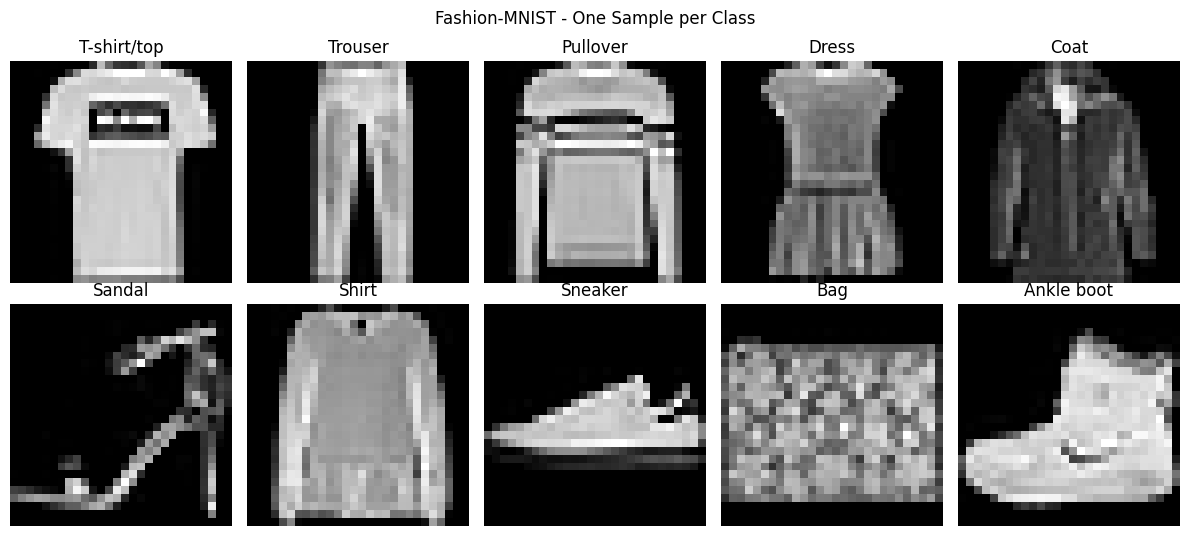

In [21]:
# show one example image from each class
fig, axes = plt.subplots(2, 5, figsize=(12, 5.5))
for i, ax in enumerate(axes.ravel()):
    idx = np.where(y_train_img == i)[0][0]      # first image of class i
    ax.imshow(X_train_img[idx], cmap="gray")
    ax.set_title(class_names[i])
    ax.axis("off")
plt.suptitle("Fashion-MNIST - One Sample per Class")
plt.tight_layout()
plt.savefig("figures/cnn_samples.png", dpi=150)
plt.show()

## 2.4 Data Preprocessing
1. **Normalise:** divide the pixel values (0–255) by 255 so they lie between 0 and 1. This helps the network train faster and more stably.
2. **Reshape:** add a channel dimension, so each image becomes 28 x 28 x 1 (grayscale).
3. **Labels:** the labels are already integers 0–9, so we use `sparse_categorical_crossentropy` and no one-hot encoding is needed.
4. **Validation split:** 10% of the training images are kept aside during training to monitor overfitting.

In [22]:
# Step 1: normalise pixel values to 0-1
X_train_cnn = X_train_img.astype("float32") / 255.0
X_test_cnn = X_test_img.astype("float32") / 255.0

# Step 2: add the channel dimension -> (samples, 28, 28, 1)
X_train_cnn = X_train_cnn.reshape(-1, 28, 28, 1)
X_test_cnn = X_test_cnn.reshape(-1, 28, 28, 1)

print("Training data shape:", X_train_cnn.shape)
print("Testing data shape :", X_test_cnn.shape)
print("New pixel range    :", X_train_cnn.min(), "to", X_train_cnn.max())

Training data shape: (60000, 28, 28, 1)
Testing data shape : (10000, 28, 28, 1)
New pixel range    : 0.0 to 1.0


## 2.5 Model Architecture
| Layer | Details |
|-------|---------|
| Conv2D | 32 filters, 3x3, ReLU |
| MaxPooling2D | 2x2 |
| Conv2D | 64 filters, 3x3, ReLU |
| MaxPooling2D | 2x2 |
| Flatten | converts feature maps into a vector |
| Dense | 128 neurons, ReLU |
| Dropout | 0.3 |
| Dense (output) | 10 neurons, Softmax |

Training settings: Adam optimiser, sparse categorical cross-entropy loss, batch size 128, up to 15 epochs with EarlyStopping on validation loss (patience 3).

In [23]:
cnn_model = keras.Sequential([
    layers.Input(shape=(28, 28, 1)),

    # block 1
    layers.Conv2D(32, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    # block 2
    layers.Conv2D(64, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    # classifier
    layers.Flatten(),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.3),
    layers.Dense(10, activation="softmax")
], name="fashion_cnn")

cnn_model.compile(optimizer="adam",
                  loss="sparse_categorical_crossentropy",
                  metrics=["accuracy"])

cnn_model.summary()

Model: "fashion_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 128)            │       204,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 225,034 (879.04 KB)

 Trainable params: 225,034 (879.04 KB)

 Non-trainable params: 0 (0.00 B)

## 2.6 Training Results and Evaluation

In [24]:
early_stop_cnn = keras.callbacks.EarlyStopping(monitor="val_loss", patience=3,
                                               restore_best_weights=True)

history_cnn = cnn_model.fit(X_train_cnn, y_train_img,
                            validation_split=0.1,
                            epochs=15,
                            batch_size=128,
                            callbacks=[early_stop_cnn],
                            verbose=2)

Epoch 1/15


422/422 - 11s - 25ms/step - accuracy: 0.7721 - loss: 0.6191 - val_accuracy: 0.8537 - val_loss: 0.3997


Epoch 2/15


422/422 - 10s - 23ms/step - accuracy: 0.8567 - loss: 0.3910 - val_accuracy: 0.8767 - val_loss: 0.3340


Epoch 3/15


422/422 - 10s - 23ms/step - accuracy: 0.8758 - loss: 0.3391 - val_accuracy: 0.8865 - val_loss: 0.3080


... (20 outputs left out)

Epoch 14/15


422/422 - 15s - 35ms/step - accuracy: 0.9395 - loss: 0.1623 - val_accuracy: 0.9183 - val_loss: 0.2288


Epoch 15/15


422/422 - 15s - 35ms/step - accuracy: 0.9417 - loss: 0.1553 - val_accuracy: 0.9238 - val_loss: 0.2243


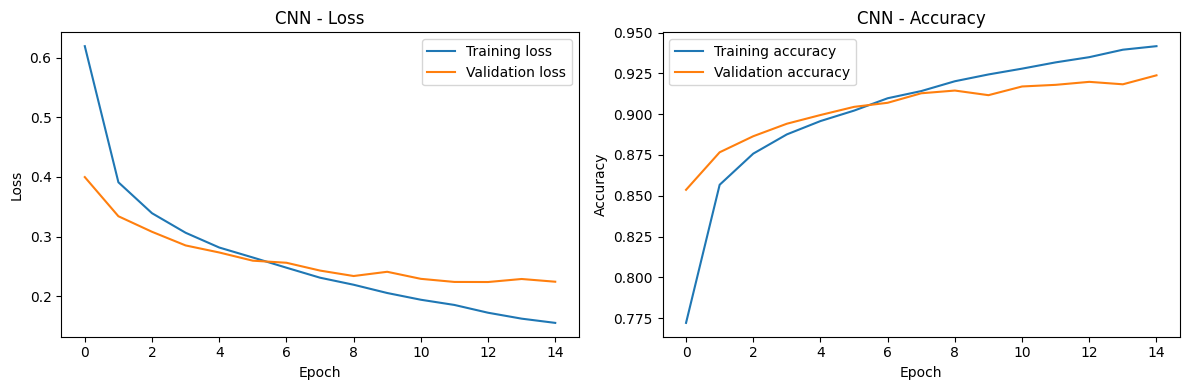

In [25]:
# training curves
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(history_cnn.history["loss"], label="Training loss")
axes[0].plot(history_cnn.history["val_loss"], label="Validation loss")
axes[0].set_title("CNN - Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend()

axes[1].plot(history_cnn.history["accuracy"], label="Training accuracy")
axes[1].plot(history_cnn.history["val_accuracy"], label="Validation accuracy")
axes[1].set_title("CNN - Accuracy")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].legend()

plt.tight_layout()
plt.savefig("figures/cnn_curves.png", dpi=150)
plt.show()

In [26]:
# evaluate on the 10,000 unseen test images
cnn_loss, cnn_acc = cnn_model.evaluate(X_test_cnn, y_test_img, verbose=0)
print("Test Loss     : %.4f" % cnn_loss)
print("Test Accuracy : %.4f" % cnn_acc)

# predictions
cnn_prob = cnn_model.predict(X_test_cnn, verbose=0)
cnn_pred = np.argmax(cnn_prob, axis=1)

print("\nClassification Report:\n")
print(classification_report(y_test_img, cnn_pred, target_names=class_names, digits=3))

Test Loss     : 0.2431
Test Accuracy : 0.9124



Classification Report:

              precision    recall  f1-score   support

 T-shirt/top      0.843     0.870     0.856      1000
     Trouser      0.998     0.976     0.987      1000
    Pullover      0.863     0.881     0.872      1000
       Dress      0.900     0.922     0.911      1000
        Coat      0.839     0.895     0.866      1000
      Sandal      0.960     0.992     0.976      1000
       Shirt      0.795     0.697     0.743      1000
     Sneaker      0.962     0.953     0.957      1000
         Bag      0.983     0.977     0.980      1000
  Ankle boot      0.978     0.961     0.969      1000

    accuracy                          0.912     10000
   macro avg      0.912     0.912     0.912     10000
weighted avg      0.912     0.912     0.912     10000



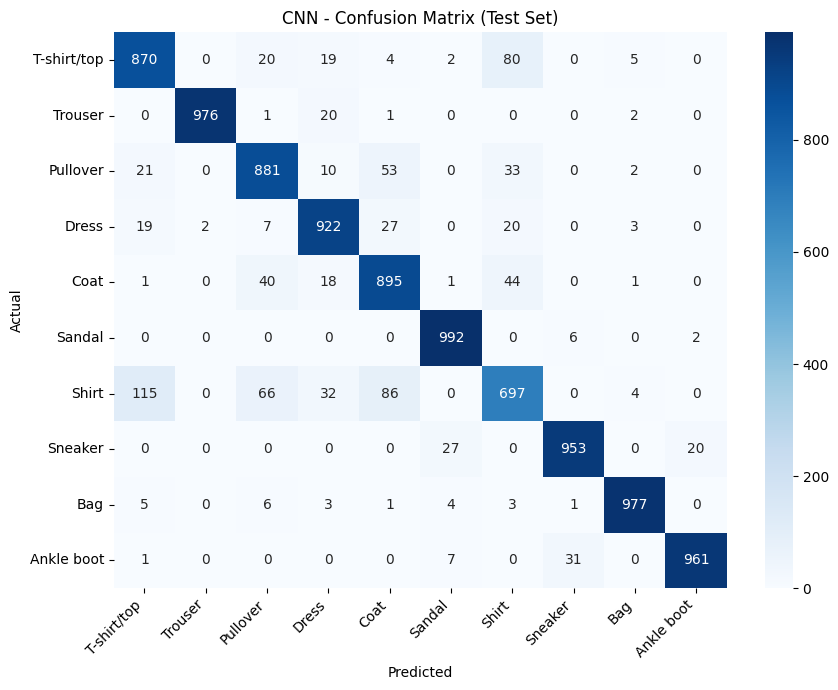

Shirt          0.697
T-shirt/top    0.870
Pullover       0.881
Coat           0.895
Dress          0.922
Sneaker        0.953
Ankle boot     0.961
Trouser        0.976
Bag            0.977
Sandal         0.992
dtype: float64


In [27]:
# confusion matrix
cm_cnn = confusion_matrix(y_test_img, cnn_pred)

plt.figure(figsize=(9, 7))
sns.heatmap(cm_cnn, annot=True, fmt="d", cmap="Blues",
            xticklabels=class_names, yticklabels=class_names)
plt.title("CNN - Confusion Matrix (Test Set)")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.savefig("figures/cnn_confusion.png", dpi=150)
plt.show()

# accuracy of each class
per_class = cm_cnn.diagonal() / cm_cnn.sum(axis=1)
print(pd.Series(per_class, index=class_names).sort_values().round(3))

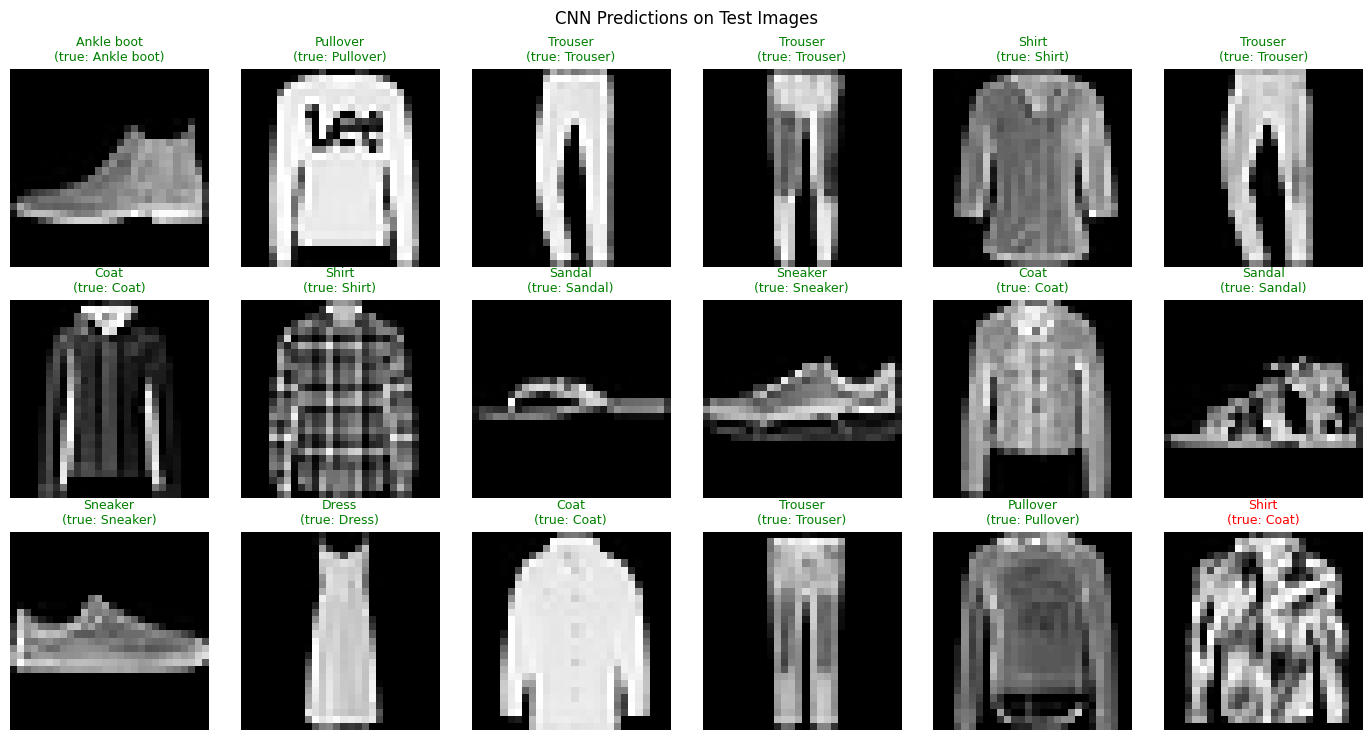

In [28]:
# look at some predictions (green title = correct, red title = wrong)
fig, axes = plt.subplots(3, 6, figsize=(14, 7.5))
for i, ax in enumerate(axes.ravel()):
    ax.imshow(X_test_img[i], cmap="gray")
    pred = cnn_pred[i]
    true = y_test_img[i]
    colour = "green" if pred == true else "red"
    ax.set_title("%s\n(true: %s)" % (class_names[pred], class_names[true]),
                 color=colour, fontsize=9)
    ax.axis("off")
plt.suptitle("CNN Predictions on Test Images")
plt.tight_layout()
plt.savefig("figures/cnn_predictions.png", dpi=150)
plt.show()

In [29]:
# the most common mistakes made by the CNN
wrong_pairs = []
for a in range(10):
    for b in range(10):
        if a != b:
            wrong_pairs.append((cm_cnn[a, b], class_names[a], class_names[b]))
wrong_pairs.sort(reverse=True)

print("Top 5 confusions (actual -> predicted):")
for count, actual, predicted in wrong_pairs[:5]:
    print("  %-12s -> %-12s : %d images" % (actual, predicted, count))

Top 5 confusions (actual -> predicted):
  Shirt        -> T-shirt/top  : 115 images
  Shirt        -> Coat         : 86 images
  T-shirt/top  -> Shirt        : 80 images
  Shirt        -> Pullover     : 66 images
  Pullover     -> Coat         : 53 images


## 2.7 Saving the Trained Model (.joblib)
The trained CNN is saved in `.joblib` format together with the list of class names, so the saved file alone is enough to turn a prediction (a number from 0 to 9) into a readable category.

In [30]:
cnn_bundle = {
    "model": cnn_model,
    "class_names": class_names,
    "input_shape": (28, 28, 1),
}
joblib.dump(cnn_bundle, "fashion_cnn_model.joblib")

print("Saved: fashion_cnn_model.joblib (%.1f KB)" % (os.path.getsize("fashion_cnn_model.joblib") / 1024))

Saved: fashion_cnn_model.joblib (2676.0 KB)


## 2.8 Inference – Classifying New Clothing Images
For inference we load the saved `.joblib` file and write a function that takes **raw images** (pixel values 0–255, exactly as a camera or website would provide them), applies the same preprocessing as in training (divide by 255, add the channel dimension), and returns the predicted category with the model's **confidence**.

In [31]:
# 1) load the saved model
loaded_cnn = joblib.load("fashion_cnn_model.joblib")

# sanity check: the loaded model must give the same results on the test set
loaded_cnn_pred = np.argmax(loaded_cnn["model"].predict(X_test_cnn, verbose=0), axis=1)
print("Same predictions as the original model:", np.array_equal(loaded_cnn_pred, cnn_pred))
print("Test accuracy of the loaded model     : %.4f" % accuracy_score(y_test_img, loaded_cnn_pred))

Same predictions as the original model: True
Test accuracy of the loaded model     : 0.9124


 Test image # True class Prediction  Confidence
         7755    Sneaker Ankle boot       0.971
         8335    Trouser    Trouser       1.000
         2252       Coat       Coat       0.789
         8968       Coat       Coat       0.997
         5781     Sandal     Sandal       1.000
         6247    Sneaker    Sneaker       1.000
         6838    Trouser    Trouser       1.000
         9442    Trouser    Trouser       1.000


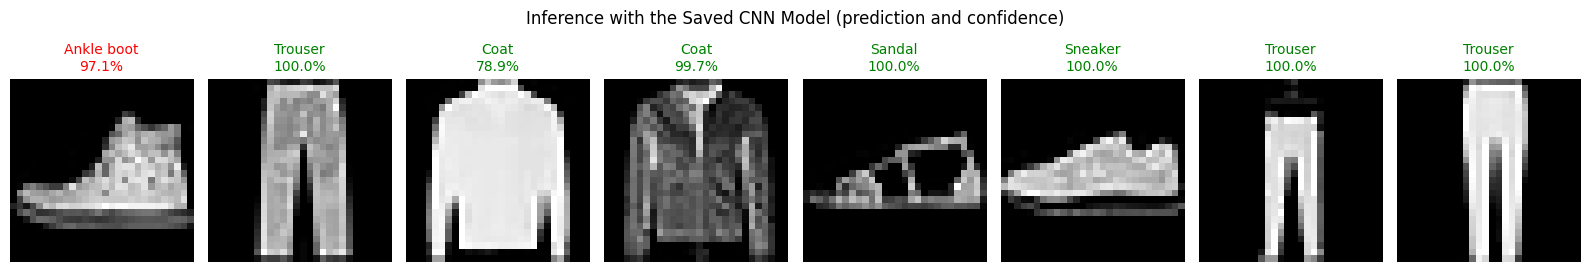


Single image: {'Prediction': 'Ankle boot', 'Confidence': 1.0}


In [32]:
# 2) the inference function: raw 28x28 images (0-255) -> category + confidence
def predict_clothing(raw_images, bundle):
    images = np.asarray(raw_images, dtype="float32")
    if images.ndim == 2:                        # a single image -> batch of one
        images = images[np.newaxis]
    images = (images / 255.0).reshape(-1, *bundle["input_shape"])
    prob = bundle["model"].predict(images, verbose=0)
    labels = np.argmax(prob, axis=1)
    return pd.DataFrame({"Prediction": [bundle["class_names"][k] for k in labels],
                         "Confidence": prob.max(axis=1).round(3)})

# 3) run it on 8 random raw test images the model never saw during training
rng = np.random.default_rng(7)
sample_idx = rng.choice(len(X_test_img), size=8, replace=False)
new_images = X_test_img[sample_idx]

inference = predict_clothing(new_images, loaded_cnn)
inference.insert(0, "True class", [class_names[k] for k in y_test_img[sample_idx]])
inference.insert(0, "Test image #", sample_idx)
print(inference.to_string(index=False))

fig, axes = plt.subplots(1, 8, figsize=(16, 3))
for ax, img, (_, row) in zip(axes, new_images, inference.iterrows()):
    ax.imshow(img, cmap="gray")
    colour = "green" if row["Prediction"] == row["True class"] else "red"
    ax.set_title("%s\n%.1f%%" % (row["Prediction"], 100 * row["Confidence"]), color=colour, fontsize=10)
    ax.axis("off")
plt.suptitle("Inference with the Saved CNN Model (prediction and confidence)")
plt.tight_layout()
plt.savefig("figures/cnn_inference.png", dpi=150)
plt.show()

# single-image inference, as it would be used for one uploaded product photo
print("\nSingle image:", predict_clothing(X_test_img[0], loaded_cnn).iloc[0].to_dict())

## 2.9 Conclusion (CNN)
- The CNN (225,034 parameters) reached a **test accuracy of 91.24%** (test loss 0.243) on 10,000 unseen images, far above the 10% of random guessing.
- The easiest classes were **Sandal, Trouser, Bag, Ankle boot and Sneaker** (recall 95.3% to 99.2%) because they have very distinct shapes.
- The hardest class was **Shirt (recall 69.7%)**. It was mostly confused with T-shirt/top (115 images), Coat (86) and Pullover (66), because these items look very similar at 28 x 28 pixels.
- Training ran for all 15 epochs and the best weights (lowest validation loss, epoch 13) were restored. Training accuracy (about 94%) is higher than validation accuracy (about 92%), which shows mild overfitting that Dropout and EarlyStopping kept under control.
- **Saved model and inference:** the CNN was saved in `fashion_cnn_model.joblib`. After reloading it gave exactly the same test predictions and classified 7 of 8 random raw images correctly; the one mistake was a Sneaker predicted as Ankle boot.
- **Business use:** an online store can use such a model to suggest or automatically check the category of every uploaded product photo, and send only low-confidence images for manual review.
- **Possible improvements:** data augmentation (flips, small shifts), a deeper CNN with Batch Normalisation, or transfer learning on higher-resolution images.

---
# Overall Summary
| | Task 1: DNN | Task 2: CNN |
|---|---|---|
| Dataset | Telco Customer Churn (7,043 rows, tabular) | Fashion-MNIST (70,000 images, 28x28) |
| Problem | Predict customer churn (binary) | Classify clothing items (10 classes) |
| Parameters | 4,161 | 225,034 |
| Test accuracy | 74.7% | 91.24% |
| Saved model | `churn_dnn_model.joblib` | `fashion_cnn_model.joblib` |
| Other key metrics | ROC-AUC 0.838, churn recall 75%, churn F1 0.61 | Macro F1 0.912, weakest class: Shirt (recall 69.7%) |

Both models learned useful patterns from their data. The CNN performed very well on the image task, while the DNN gives a practical, recall-focused churn detector for a harder, imbalanced tabular problem.

Both trained models were saved as `.joblib` files and reloaded in the inference steps (sections 1.8 and 2.8), which confirmed that the saved files give exactly the same predictions as the original models and can classify new, unseen data.
